# 3D-07 — Générer les niveaux d'une hiérarchie **ensemble** : flow matching discret joint

[← Tradeoffs d'optimisation 3DGS (3D-05)](3D-05-3DGS-Optimization-Tradeoffs.ipynb) | [← Démo interactive Spark (3D-06)](3D-06-Spark-Interactive-Demo.md) | [← Série GenAI/3D](README.md)

> **Ce que fait ce notebook** : la série a construit le **rendu** neuronal (NeRF puis gaussiennes splatting). Ce carnet ouvre le versant **génération** avec [JoVox](https://arxiv.org/abs/2611.10690) (Tang, Chen, Wonka — KAUST), et n'en implémente que le **cœur algorithmique**, from scratch et sur CPU : un **flow matching discret** qui apprend la loi **jointe** de tous les niveaux d'une hiérarchie de voxels, au lieu d'une loi par niveau. Le jouet tient en une grille 4³ → 8³ → 16³ et quatre formes possibles. On y mesure une seule chose, mais exactement : **au moment où une cellule grossière est décidée, combien de cellules fines sont déjà connues autour d'elle** — 63,4 % en joint, 0 % en séquentiel, où c'est structurellement impossible. La qualité d'image, elle, ne bouge pas à cette échelle : le carnet le dit et explique pourquoi.
>
> **Source** : Tang, Chen, Wonka — *JoVox: Joint Hierarchical Flow Matching for Lightweight Voxel Generation*, arXiv 2611.10690 (2026). PDF archivé dans le gisement `G:\Mon Drive\MyIA\IA\Bibliographie IA\ComputerGraphics\`. Toutes les valeurs de cet article citées ici sont marquées **RAPPORTÉES** ; seules les mesures de ce carnet sont rejouées.

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
from scipy.ndimage import convolve
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

NIVEAUX = [0, 1, 2]
TAILLES = {0: 4, 1: 8, 2: 16}      # 4^3, 8^3, 16^3 cellules
FIN = 16                            # resolution du niveau le plus fin
print(f"torch {torch.__version__} / numpy {np.__version__} -- execution CPU, aucun GPU requis")

torch 2.14.0+cpu / numpy 2.4.2 -- execution CPU, aucun GPU requis


## 1. Le problème : le grossier est décidé avec le moins d'information

Une méthode hiérarchique factorise la loi des occupations en

$$p(O_0 \mid c)\prod_{l=1}^{L} p(O_l \mid O_{l-1}, c)$$

Chaque niveau n'est donc décidé qu'à partir des niveaux **plus grossiers** — qui sont précisément ceux qui portent le moins d'information sur la forme. Le niveau 0 décide où *toute* la finesse pourra apparaître, et il n'est jamais revisité : ses erreurs sont héritées.

Le jouet ci-dessous rend ce défaut mesurable. La famille de formes est une **coque sphérique** privée d'une **calotte** sur l'un des quatre côtés (x+, x−, y+, y−). Le rayon et la profondeur de coupe sont choisis pour que, à la résolution du niveau 0 (cellules de 4 unités), **les quatre variantes soient indiscernables** : la calotte tombe entièrement dans une cellule déjà occupée par la coque.

mode 0 : niveau 0 = 8 cellules occupees sur 64 | niveau 1 = 24 cellules occupees sur 512 | niveau 2 = 68 cellules occupees sur 4096
mode 1 : niveau 0 = 8 cellules occupees sur 64 | niveau 1 = 24 cellules occupees sur 512 | niveau 2 = 68 cellules occupees sur 4096
mode 2 : niveau 0 = 8 cellules occupees sur 64 | niveau 1 = 24 cellules occupees sur 512 | niveau 2 = 68 cellules occupees sur 4096
mode 3 : niveau 0 = 8 cellules occupees sur 64 | niveau 1 = 24 cellules occupees sur 512 | niveau 2 = 68 cellules occupees sur 4096

Occupations identiques entre mode 0 et mode 1, niveau par niveau : [True, False, False]


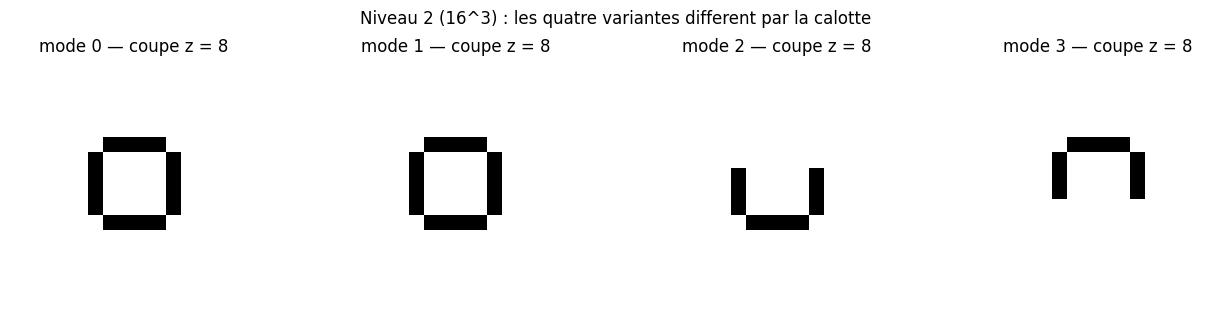

In [2]:
CENTRE, RAYON, COUPE = 8.0, 3.0, 2.0

def forme_fine(mode):
    """Coque spherique de rayon RAYON, privee d'une calotte sur l'un des 4 cotes."""
    idx = np.arange(FIN) + 0.5
    X, Y, Z = np.meshgrid(idx, idx, idx, indexing="ij")
    r = np.sqrt((X - CENTRE) ** 2 + (Y - CENTRE) ** 2 + (Z - CENTRE) ** 2)
    coque = np.abs(r - RAYON) <= 0.5
    axes = [(X, 1.0), (X, -1.0), (Y, 1.0), (Y, -1.0)]
    a, sgn = axes[mode]
    retire = ((a - CENTRE) * sgn) > (RAYON - COUPE)
    return coque & ~retire

def hierarchie(occ_fine):
    """Une cellule de niveau l est occupee si l'une de ses descendantes fines l'est."""
    h = {2: occ_fine}
    for l in (1, 0):
        k = FIN // TAILLES[l]
        h[l] = occ_fine.reshape(TAILLES[l], k, TAILLES[l], k, TAILLES[l], k).any(axis=(1, 3, 5))
    return h

FORMES = [hierarchie(forme_fine(m)) for m in range(4)]
for m, h in enumerate(FORMES):
    print(f"mode {m} : " + " | ".join(f"niveau {l} = {int(h[l].sum())} cellules occupees sur {TAILLES[l] ** 3}" for l in NIVEAUX))

identiques = [bool((FORMES[0][l] == FORMES[1][l]).all()) for l in NIVEAUX]
print("\nOccupations identiques entre mode 0 et mode 1, niveau par niveau :", identiques)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for m in range(4):
    axes[m].imshow(FORMES[m][2][8], cmap="Greys", origin="lower")
    axes[m].set_title(f"mode {m} — coupe z = 8")
    axes[m].axis("off")
plt.suptitle("Niveau 2 (16^3) : les quatre variantes different par la calotte")
plt.tight_layout()
plt.show()

### Lecture du résultat

La liste `identiques` vaut `[True, False, False]`. **Le niveau 0 ne distingue aucune des quatre formes** : ses cellules occupées sont les mêmes dans les quatre cas. C'est exactement la situation que décrit l'article — un niveau grossier qui décide du support de toute la finesse alors qu'il ne porte presque aucune information sur elle.

Conséquence directe pour un générateur séquentiel : au moment où il décide le niveau 1, la seule information dont il dispose est un niveau 0 strictement identique dans les quatre cas. Il ne peut donc que produire la **marginale** sur les quatre variantes — et le niveau 2 héritera de ce choix, sans jamais le réviser.

## 2. Flow matching discret : transporter du masque vers la forme

On note $\mathbf{x} = (x_1,\dots,x_n)$ un tenseur d'occupations, chaque $x_i \in \mathcal{T} = \{0,1\}$. Le flow matching discret (Gat et al. 2024 ; Campbell et al. 2024) transporte une **source** vers les **données** le long d'un temps $t \in [0,1]$.

Le choix de source retenu ici est la **source masquée** : $\mathbf{x}_0 = (\varnothing,\dots,\varnothing)$, avec $\varnothing \notin \mathcal{T}$ le symbole de masque. Le chemin devient un simple **masquage** : sachant $\mathbf{x}_1$, chaque entrée garde sa valeur avec probabilité $t$ et est masquée sinon,

$$p_{t\mid 1}(\mathbf{x}_t \mid \mathbf{x}_1) = \prod_{i=1}^{n}\Big[t\,\delta(x^i_t, x^i_1) + (1-t)\,\delta(x^i_t, \varnothing)\Big]. \tag{1}$$

Le réseau prédit $p_\theta(x^i_1 \mid \mathbf{x}_t, t)$ pour chaque entrée, et la perte vaut

$$\ell_i = \begin{cases} -\log p_\theta(x^i_1 \mid \mathbf{x}_t, t) & \text{si } x^i_t = \varnothing \quad\text{(entropie croisée)}\\ 1 - p_\theta(x^i_1 \mid \mathbf{x}_t, t) & \text{sinon} \quad\text{(pénalité sur la valeur observée)} \end{cases} \tag{3}$$

Les deux branches ne sont **pas** la même fonction : la première est une entropie croisée (logarithme), la seconde une pénalité **linéaire**. C'est la vérification de la cellule suivante.

In [3]:
def perte_entree(p, cible, masque):
    """Eq. (3) : -log p sur une entree masquee, 1 - p(valeur observee) sinon."""
    p = np.clip(p, 1e-6, 1 - 1e-6)
    valeur = np.where(cible > 0, p, 1 - p)          # probabilite de la VRAIE valeur
    ce = -np.log(valeur)                             # branche masquee
    penalite = 1.0 - valeur                          # branche non masquee
    return np.where(masque, ce, penalite)

p_ex = np.array([0.90, 0.20, 0.75])
c_ex = np.array([1, 0, 1])
m_ex = np.array([True, False, True])

l_masq = perte_entree(p_ex, c_ex, m_ex)
print("entree 0 (masquee, vraie valeur 1, p = 0.90) : -log 0.90 =", round(float(l_masq[0]), 4))
print("entree 1 (revelee, vraie valeur 0, p = 0.20) : 1 - p(0)  =", round(float(l_masq[1]), 4), "= 1 - 0.80")
print("entree 2 (masquee, vraie valeur 1, p = 0.75) : -log 0.75 =", round(float(l_masq[2]), 4))

meme_p = np.array([0.8])
print("\nA probabilite egale (0.80, vraie valeur 1), les deux branches donnent :",
      round(float(perte_entree(meme_p, np.array([1]), np.array([True]))[0]), 4), "(masquee) contre",
      round(float(perte_entree(meme_p, np.array([1]), np.array([False]))[0]), 4), "(revelee)")

entree 0 (masquee, vraie valeur 1, p = 0.90) : -log 0.90 = 0.1054
entree 1 (revelee, vraie valeur 0, p = 0.20) : 1 - p(0)  = 0.2 = 1 - 0.80
entree 2 (masquee, vraie valeur 1, p = 0.75) : -log 0.75 = 0.2877

A probabilite egale (0.80, vraie valeur 1), les deux branches donnent : 0.2231 (masquee) contre 0.2 (revelee)


### Lecture du résultat

Deux nombres différents pour la même probabilité — 0,2231 contre 0,2000. La branche masquée est une **vraie** entropie croisée, qui explose quand le modèle est confiant et faux ; la branche révélée est une pénalité **bornée par 1**. Ce déséquilibre est voulu : une entrée déjà révélée n'a pas à être re-prédite, elle doit seulement rester probable. C'est ce qui permet d'entraîner le réseau sur des états **partiellement** résolus, donc sur toutes les combinaisons de fractions entre niveaux (section 4).

## 3. La hiérarchie jointe : une seule loi pour tous les niveaux

Le pas décisif de JoVox est de ne pas factoriser. Les entrées du flow matching deviennent les **occupations de tous les niveaux**, et le masquage respecte la hiérarchie : **masquer une cellule retire toutes les cellules qu'elle contient**, puisque leurs occupations révéleraient la sienne. Avec un vecteur de fractions $t = (t_l)_{l \in J}$,

$$p_{t\mid 1}(\mathbf{x}_t \mid \mathbf{x}_1) = \prod_{l \in J}\ \prod_{i \in C_l(\mathbf{x}_t)}\Big[t_l\,\delta(x^i_{t_l}, x^i_1) + (1-t_l)\,\delta(x^i_{t_l}, \varnothing)\Big] \tag{5}$$

Les $t_l$ sont tirés **indépendamment** : le réseau voit donc des états où le niveau 0 est presque complet et le niveau 2 à peine commencé — et l'inverse. C'est cette invariance qui rend représentable l'ordonnancement de la section 6.

Les niveaux fins comptant beaucoup plus de cellules que les grossiers, une perte sommée serait dominée par eux. L'article **moyenne d'abord par niveau, puis sur les niveaux** :

$$\mathcal{L} = \mathbb{E}\left[\frac{1}{|J(\mathbf{x}_t)|}\sum_{l \in J(\mathbf{x}_t)} \frac{1}{(1-t_l)\,|C_l(\mathbf{x}_t)|}\sum_{i \in C_l(\mathbf{x}_t)} \ell_i\right] \tag{8}$$

In [4]:
def etat_masque(x1, t, rng):
    """Eq. (5) : masquage par niveau ; masquer une cellule emporte ses descendants."""
    st = {l: np.full((TAILLES[l],) * 3, -1, np.int8) for l in NIVEAUX}
    garde = {l: rng.random((TAILLES[l],) * 3) < t[l] for l in NIVEAUX}
    st[0] = np.where(garde[0], x1[0], -1).astype(np.int8)
    for l in (1, 2):
        parent_occ = st[l - 1] == 1
        rep = parent_occ.repeat(2, axis=0).repeat(2, axis=1).repeat(2, axis=2)
        st[l] = np.where(rep & garde[l], x1[l], -1).astype(np.int8)
    return st

def vivantes(st):
    """Cellules dont l'occupation existe dans l'etat (parent revele occupe)."""
    v = {0: np.ones((TAILLES[0],) * 3, bool)}
    for l in (1, 2):
        parent_occ = st[l - 1] == 1
        v[l] = parent_occ.repeat(2, axis=0).repeat(2, axis=1).repeat(2, axis=2)
    return v

def boite3(a):
    return convolve(a.astype(np.float32), np.ones((3, 3, 3), np.float32), mode="constant")

def caracteristiques(st, viv):
    """19 features par cellule vivante : position, niveau, position intra-parent,
    etat du parent, voisinage 3x3x3, part de finesse connue dans le volume, fractions globales."""
    lignes, index = [], []
    glob = [float(((st[l] >= 0) & viv[l]).sum()) / max(int(viv[l].sum()), 1) for l in NIVEAUX]
    occ2 = (st[2] == 1).astype(np.float32)
    kno2 = (st[2] >= 0).astype(np.float32)
    for l in NIVEAUX:
        n = TAILLES[l]
        k = FIN // n
        if k > 1:
            fo = occ2.reshape(n, k, n, k, n, k).sum(axis=(1, 3, 5)) / k ** 3
            fk = kno2.reshape(n, k, n, k, n, k).sum(axis=(1, 3, 5)) / k ** 3
        else:
            fo = np.zeros((n, n, n), np.float32)
            fk = np.zeros((n, n, n), np.float32)
        s = st[l]
        occ = (s == 1).astype(np.float32)
        emp = (s == 0).astype(np.float32)
        nb_o = (boite3(occ) - occ) / 26.0
        nb_e = (boite3(emp) - emp) / 26.0
        par = (np.ones((n, n, n), np.float32) if l == 0 else
               st[l - 1].repeat(2, axis=0).repeat(2, axis=1).repeat(2, axis=2).astype(np.float32))
        ii, jj, kk = np.meshgrid(np.arange(n), np.arange(n), np.arange(n), indexing="ij")
        pos = np.stack([(ii + 0.5) / n, (jj + 0.5) / n, (kk + 0.5) / n], -1).astype(np.float32)
        niv = np.zeros((n, n, n, 3), np.float32); niv[..., l] = 1.0
        sub = np.stack([(ii % 2) * 0.5 + 0.25, (jj % 2) * 0.5 + 0.25,
                        (kk % 2) * 0.5 + 0.25], -1).astype(np.float32)
        par_oh = np.stack([(par < 0), (par == 0), (par > 0)], -1).astype(np.float32)
        gl = np.broadcast_to(np.array(glob, np.float32), (n, n, n, 3))
        feat = np.concatenate([pos, niv, sub, par_oh, nb_o[..., None], nb_e[..., None],
                               fo[..., None], fk[..., None], gl], -1)
        m = viv[l]
        lignes.append(feat[m]); index.append((l, np.argwhere(m)))
    return np.concatenate(lignes, 0), index

class Reseau(nn.Module):
    def __init__(self, d=19, h=96):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

print("defini : etat_masque, vivantes, caracteristiques (19 variables), Reseau(19 -> 96 -> 96 -> 1)")

defini : etat_masque, vivantes, caracteristiques (19 variables), Reseau(19 -> 96 -> 96 -> 1)


## 4. Entraînement : prédire n'importe quel niveau depuis n'importe quel état

À chaque pas on tire six formes, un vecteur $t$ **par niveau** et par forme, on masque, on construit les caractéristiques, et on applique l'équation (8) : moyenne par niveau, puis moyenne sur les niveaux, pondérée par $1/(1-t_l)$.

Le réseau est un perceptron à deux couches cachées (96 unités) sur 19 caractéristiques construites à la main — position, niveau, position intra-parent, état du parent, voisinage 3×3×3, part de finesse connue dans son volume, et les fractions globales par niveau. L'article utilise un **transformer** avec des embeddings appris : c'est la simplification déclarée, qui isole le **cadre algorithmique** de la capacité du modèle.

entrainement : 48.6 s pour 1600 pas (6 formes par pas)
perte, un point tous les 100 pas :
  pas   :      0    100    200    300    400    500    600    700    800    900   1000   1100   1200   1300   1400   1500
  perte :  2.320  1.310  1.191  0.770  1.251  0.656  0.675  1.162  0.600  0.603  0.564  0.569  0.733  0.686  0.388  0.511


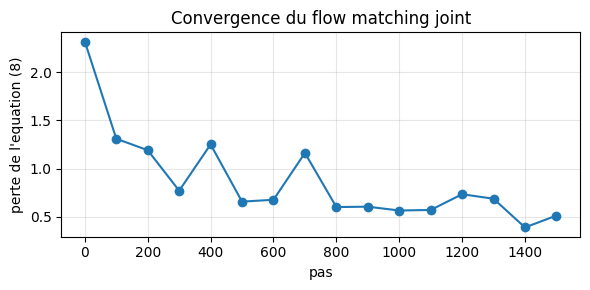

In [5]:
def entrainer(pas=1600, graine=0):
    rng = np.random.default_rng(graine)
    torch.manual_seed(graine)
    net = Reseau()
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    hist = []
    t0 = time.time()
    for s in range(pas):
        X, Y, groupes = [], [], []
        for m in rng.integers(0, 4, size=6):
            t = rng.uniform(0.05, 1.0, size=3)
            st = etat_masque(FORMES[m], t, rng)
            f, idx = caracteristiques(st, vivantes(st))
            y = np.concatenate([FORMES[m][l][ix[:, 0], ix[:, 1], ix[:, 2]].astype(np.float32)
                                for (l, ix) in idx])
            X.append(f); Y.append(y); groupes.append((idx, t))
        logits = net(torch.tensor(np.concatenate(X), dtype=torch.float32))
        cible = torch.tensor(np.concatenate(Y), dtype=torch.float32)
        bce = nn.functional.binary_cross_entropy_with_logits(logits, cible, reduction="none")
        perte, off, n_termes = 0.0, 0, 0
        for (idx, t) in groupes:
            for (l, ix) in idx:
                k = len(ix)
                if k:
                    w = min(1.0 / max(1.0 - t[l], 0.1), 10.0)
                    perte = perte + bce[off:off + k].mean() * w
                    n_termes += 1
                off += k
        perte = perte / max(n_termes, 1)
        opt.zero_grad(); perte.backward(); opt.step()
        if s % 100 == 0:
            hist.append((s, float(perte.detach())))
    return net, time.time() - t0, hist

reseau, duree, hist = entrainer()
print(f"entrainement : {duree:.1f} s pour 1600 pas (6 formes par pas)")
print("perte, un point tous les 100 pas :")
print("  pas   :", " ".join(f"{s:>6d}" for (s, _) in hist))
print("  perte :", " ".join(f"{v:>6.3f}" for (_, v) in hist))

plt.figure(figsize=(6, 3))
plt.plot([s for (s, _) in hist], [v for (_, v) in hist], marker="o")
plt.xlabel("pas"); plt.ylabel("perte de l'equation (8)")
plt.title("Convergence du flow matching joint")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Lecture du résultat

La perte ne descend pas régulièrement et ne converge pas vers zéro : elle **oscille**. La liste imprimée va de 2,32 au premier pas à 0,39 au pas 1500, avec des remontées à 1,31 et 1,25 en cours de route. Ce n'est pas un défaut d'optimisation. Chaque pas tire un nouveau couple (forme, fractions) et repondère par $1/(1-t_l)$, qui varie d'un facteur 10 selon le tirage : une perte élevée sur un état presque vide et une perte basse sur un état presque complet ne mesurent pas la même difficulté. C'est la contrepartie assumée de l'équation (8) — les états très masqués sont peu nombreux, donc fortement pondérés.

Le test qui compte n'est pas la perte mais la **séparabilité** : sur un état entièrement masqué, le réseau doit retrouver le support grossier de la forme.

In [6]:
def predire(net, st):
    viv = vivantes(st)
    f, idx = caracteristiques(st, viv)
    p = torch.sigmoid(net(torch.tensor(f, dtype=torch.float32))).detach().numpy()
    out = {l: np.zeros((TAILLES[l],) * 3, np.float32) for l in NIVEAUX}
    off = 0
    for (l, m) in idx:
        v = p[off:off + len(m)]
        out[l][m[:, 0], m[:, 1], m[:, 2]] = v
        off += len(m)
    return out, viv

st_vide = {l: np.full((TAILLES[l],) * 3, -1, np.int8) for l in NIVEAUX}
p0, viv0 = predire(reseau, st_vide)
occ0 = FORMES[0][0]
print("Niveau 0, etat entierement masque :")
print(f"  probabilite moyenne sur les {int(occ0.sum()):>3d} cellules occupees : {p0[0][occ0].mean():.3f}")
print(f"  probabilite moyenne sur les {int((~occ0).sum()):>3d} cellules vides    : {p0[0][~occ0].mean():.3f}")
print(f"  cellules au-dessus de 0.5 : {int((p0[0] > 0.5).sum())}")

Niveau 0, etat entierement masque :
  probabilite moyenne sur les   8 cellules occupees : 0.964
  probabilite moyenne sur les  56 cellules vides    : 0.007
  cellules au-dessus de 0.5 : 8


### Lecture du résultat

Sur un état **entièrement** masqué, le réseau sépare franchement les deux populations : la probabilité moyenne vaut 0,964 sur les cellules occupées et 0,007 sur les vides, et exactement 8 cellules passent le seuil de 0,5 — le nombre que la forme en compte. Il a donc appris le support grossier, ce qui est le minimum pour que la comparaison de la section 7 ait un sens : si le niveau 0 n'était pas appris, un écart entre échantillonneurs ne dirait rien du cadre, seulement de la faiblesse du réseau.

Rien n'est appris par cœur : les caractéristiques sont génériques (position, voisinage, parent) et les quatre formes partagent le même réseau.

## 5. Prédiction à deux niveaux : ce que la formulation change au coût

Une cellule de niveau $l$ couvre $4^3$ cellules de niveau $l+2$. Prédire directement leur occupation demanderait une entrée à $2^{64}$ valeurs — inexploitable. JoVox découpe cette occupation en **huit codes de 8 bits**, un par fille de niveau $l+1$, chacun décrivant les huit cellules de niveau $l+2$ qu'il contient : la sortie devient huit distributions sur $2^8$ valeurs.

Le second effet est un **facteur deux sur le nombre de niveaux traités** : seules les cellules des niveaux pairs portent un token, les niveaux impairs n'étant plus jamais traités (article, section 4.2).

In [7]:
valeurs_directes = 2 ** 64
valeurs_decoupees = 8 * (2 ** 8)
print("occupation directe des 4^3 cellules deux niveaux plus fin :", f"2^64 = {valeurs_directes:.3e} valeurs")
print("decoupage en 8 codes de 8 bits (un par fille)            :", f"8 x 2^8 = {valeurs_decoupees} valeurs")
print("rapport des tailles de sortie                             :", f"{valeurs_directes / valeurs_decoupees:.3e}")

L = 4
print(f"\nAvec L = {L} niveaux (grille 64^3, le reglage de l'article) :")
print(f"  prediction a un niveau    : {L} niveaux traites (0, 1, 2, 3)")
print(f"  prediction a deux niveaux : {L // 2} niveaux traites (0, 2) = la moitie")

occupation directe des 4^3 cellules deux niveaux plus fin : 2^64 = 1.845e+19 valeurs
decoupage en 8 codes de 8 bits (un par fille)            : 8 x 2^8 = 2048 valeurs
rapport des tailles de sortie                             : 9.007e+15

Avec L = 4 niveaux (grille 64^3, le reglage de l'article) :
  prediction a un niveau    : 4 niveaux traites (0, 1, 2, 3)
  prediction a deux niveaux : 2 niveaux traites (0, 2) = la moitie


### Lecture du résultat

Le découpage fait passer la sortie d'une entrée de $2^{64}$ valeurs — impossible — à huit distributions de 256 valeurs, soit un rapport de l'ordre de $10^{16}$. Ce n'est pas une approximation : c'est la **même** information, réindexée par fille. L'article mesure que cette formulation ne fait pas que réduire le coût, elle **améliore** aussi la fidélité (**RAPPORTÉ**, section 5.4) ; ce carnet ne rejoue pas cette ablation, qui demande l'échelle 64³ et le transformer complet.

Le facteur deux est arithmétique et se lit sur place : c'est le nombre de niveaux parcourus qui est divisé, pas le nombre de cellules produites.

## 6. Ordonnancement et remasquage : réviser une décision ancienne

À l'inférence, chaque niveau $l$ suit la fraction cible

$$\kappa_l(k) = \min\left(\frac{k}{N_l}, 1\right)^{\rho} \tag{9}$$

qui atteint 1 au pas $N_l \le N$, avec $N_1 \le N_2 \le \dots \le N_{L-1} = N$ : les niveaux grossiers se complètent plus tôt. $\rho > 1$ fait démarrer lentement — les premiers pas, où le modèle est le moins sûr, révèlent donc très peu de cellules à la fois.

Chaque pas fait trois choses, dans cet ordre : (1) chaque niveau **remasque ses cellules révélées les plus anciennes** pour revenir à $\kappa_l(k-1)$ — ce sont celles qui ont été décidées avec le moins de voisines connues ; (2) le réseau prédit toutes les cellules masquées ; (3) chaque niveau révèle des cellules tirées au hasard jusqu'à $\kappa_l(k+1)$, en échantillonnant dans les probabilités prédites.

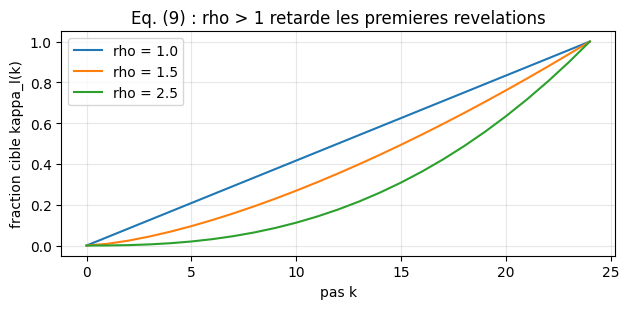

Fraction cible au premier pas (k+1 = 1, N_l = 24) :
  rho = 1.0 : 0.0417 des cellules revelees
  rho = 1.5 : 0.0085 des cellules revelees
  rho = 2.5 : 0.0004 des cellules revelees


In [8]:
def kappa(k, Nl, rho):
    return min(k / Nl, 1.0) ** rho

plt.figure(figsize=(6.4, 3.2))
for rho in (1.0, 1.5, 2.5):
    ks = np.arange(0, 25)
    plt.plot(ks, [kappa(k, 24, rho) for k in ks], label=f"rho = {rho}")
plt.xlabel("pas k"); plt.ylabel("fraction cible kappa_l(k)")
plt.title("Eq. (9) : rho > 1 retarde les premieres revelations")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print("Fraction cible au premier pas (k+1 = 1, N_l = 24) :")
for rho in (1.0, 1.5, 2.5):
    print(f"  rho = {rho} : {kappa(1, 24, rho):.4f} des cellules revelees")

### Lecture du résultat

Avec $\rho = 2{,}5$, le premier pas ne révèle que 0,0004 de chaque niveau, contre 0,0417 pour $\rho = 1$ — un facteur d'environ 100. C'est le levier qui permet au cadre joint d'être **utilisé** : tant qu'aucune cellule n'est décidée, aucune décision n'est à hériter. Avec $\rho = 1$ la révélation est quasi linéaire, et les cellules grossières partent avant que la finesse n'existe.

## 7. Ce que le cadre change, mesuré exactement

On échantillonne avec le **même réseau entraîné**, en ne changeant que l'ordonnancement :

- **joint** : $N_l = (24, 24, 24)$, remasquage actif — les trois niveaux progressent ensemble, et une cellule grossière peut être décidée alors que des cellules fines voisines sont déjà connues ;
- **séquentiel** : $N_l = (1, 12, 24)$, sans remasquage — le niveau 0 est entièrement décidé au premier pas, puis le niveau 1, puis le niveau 2. C'est la factorisation $p(O_0)\prod_l p(O_l \mid O_{l-1})$.

La mesure est prise **au moment de la décision** : pour chaque décision d'une cellule de niveau 0, combien de cellules du niveau le plus fin sont déjà connues dans son voisinage 3×3×3 ? En joint, une cellule remasquée puis re-décidée compte deux décisions : c'est voulu, chacune est jugée sur l'information disponible à cet instant.

In [9]:
def echantillonner(net, Ns, N, rho=1.5, remasquage=True, rng=None, trace=None):
    rng = rng or np.random.default_rng(0)
    st = {l: np.full((TAILLES[l],) * 3, -1, np.int8) for l in NIVEAUX}
    age = {l: np.zeros((TAILLES[l],) * 3, np.int32) for l in NIVEAUX}
    for k in range(N):
        if remasquage and k >= 1:
            for l in NIVEAUX:
                viv = vivantes(st)
                m = viv[l] & (st[l] >= 0)
                n_un = int(m.sum())
                if n_un:
                    cible = int(kappa(k - 1, Ns[l], rho) * viv[l].sum())
                    if n_un > cible:
                        cand = np.argwhere(m)
                        vieux = np.argsort(age[l][m])[:n_un - cible]
                        sel = cand[vieux]
                        st[l][sel[:, 0], sel[:, 1], sel[:, 2]] = -1
        probs, viv = predire(net, st)
        for l in NIVEAUX:
            m = viv[l] & (st[l] < 0)
            kmax = int(round(kappa(k + 1, Ns[l], rho) * viv[l].sum()))
            besoin = max(kmax - int((viv[l] & (st[l] >= 0)).sum()), 0)
            cand = np.argwhere(m)
            if besoin <= 0 or len(cand) == 0:
                continue
            sel = cand[rng.choice(len(cand), besoin, replace=False)] if besoin < len(cand) else cand
            if trace is not None and l == 0:
                kk = FIN // TAILLES[0]
                for c in sel:
                    a0, b0, c0 = (c[0] - 1) * kk, (c[1] - 1) * kk, (c[2] - 1) * kk
                    blk = st[2][max(a0, 0):a0 + 3 * kk, max(b0, 0):b0 + 3 * kk, max(c0, 0):c0 + 3 * kk]
                    trace.append((k, int((blk >= 0).sum())))
            pv = probs[l][sel[:, 0], sel[:, 1], sel[:, 2]]
            st[l][sel[:, 0], sel[:, 1], sel[:, 2]] = (pv > 0.5).astype(np.int8)
            age[l][sel[:, 0], sel[:, 1], sel[:, 2]] = k
    # completion : une cellule revelee occupee en fin de course n'a pas encore ses enfants
    for _ in range(4):
        viv = vivantes(st)
        if not any((viv[l] & (st[l] < 0)).any() for l in NIVEAUX):
            break
        probs, viv = predire(net, st)
        for l in NIVEAUX:
            m = viv[l] & (st[l] < 0)
            if m.any():
                st[l][m] = (probs[l][m] > 0.5).astype(np.int8)
    return st

resultats = {}
for nom, Ns, rem in (("joint", (24, 24, 24), True), ("sequentiel", (1, 12, 24), False)):
    rng = np.random.default_rng(7)
    trace, formes = [], []
    for _ in range(8):
        st = echantillonner(reseau, Ns, 24, rho=1.5, remasquage=rem, rng=rng, trace=trace)
        formes.append(st[2] == 1)
    ev = [e for (_, e) in trace]
    resultats[nom] = dict(avec=float(np.mean([e > 0 for e in ev])), mediane=float(np.median(ev)),
                          decisions=len(ev), formes=formes)
    print(f"{nom:<11} decisions de niveau 0 : {len(ev):>5} | "
          f"avec finesse voisine deja connue : {100 * resultats[nom]['avec']:5.1f} % | "
          f"mediane = {resultats[nom]['mediane']:.0f} cellules fines")

joint       decisions de niveau 0 :  1088 | avec finesse voisine deja connue :  63.4 % | mediane = 6 cellules fines


sequentiel  decisions de niveau 0 :   512 | avec finesse voisine deja connue :   0.0 % | mediane = 0 cellules fines


### Lecture du résultat

C'est la mesure centrale du carnet, et elle est **structurelle**, pas statistique : en séquentiel le taux vaut exactement **0 %**. Aucune cellule fine ne peut exister au moment où le niveau 0 est décidé, puisque le niveau 0 est décidé avant tout le reste — la hiérarchie est une simple cascade. En joint, **63,4 %** des décisions grossières sont prises alors que des cellules fines voisines sont déjà connues, avec une médiane de 6 cellules.

Autrement dit : le cadre joint ne rend pas le réseau meilleur, il rend l'**information fine disponible au moment où la décision grossière est prise**. La factorisation, elle, rend cette information structurellement absente — c'est exactement ce que l'article reproche aux méthodes hiérarchiques : les niveaux grossiers y sont générés avec le moins d'information sur la forme, et ne sont jamais revisités.

## 8. La qualité, elle, ne bouge pas à cette échelle

La mesure ci-dessus dit ce que le cadre **permet**. Elle ne dit pas qu'il produit de meilleures formes ici. On compare donc les deux échantillonneurs sur le meilleur recouvrement (IoU) avec l'une des quatre formes valides.

joint       IoU meilleur appariement : 0.377 | cellules generees :   94.8 (les formes en comptent 68)
sequentiel  IoU meilleur appariement : 0.413 | cellules generees :  103.5 (les formes en comptent 68)


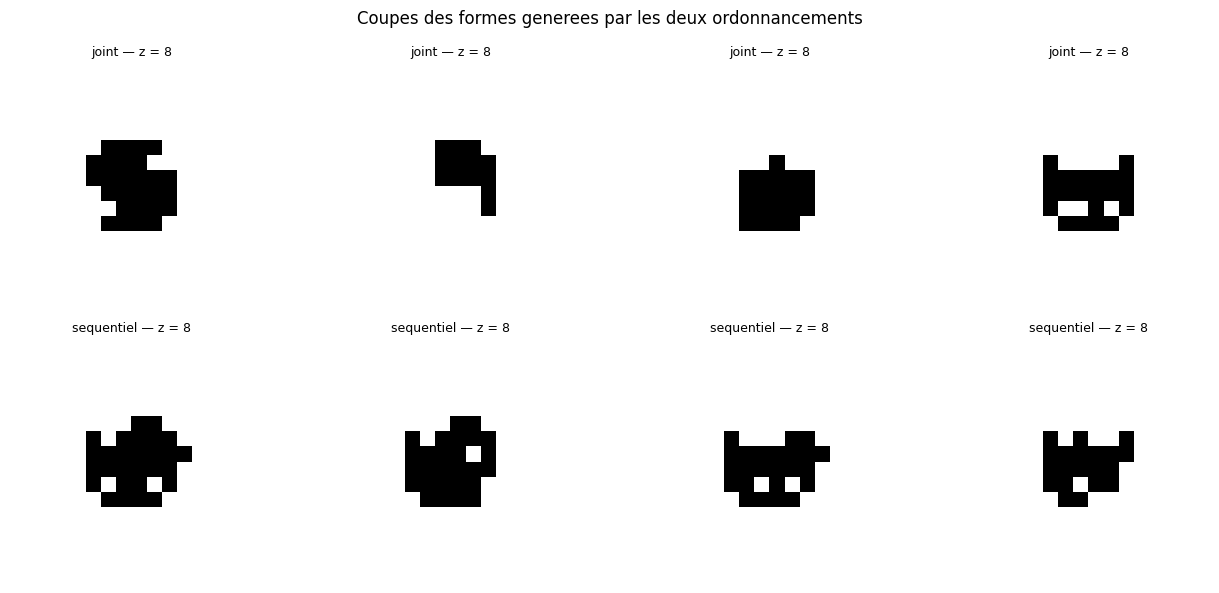

In [10]:
def iou(a, b):
    return float((a & b).sum()) / max(int((a | b).sum()), 1)

for nom, r in resultats.items():
    scores = [max(iou(f, FORMES[m][2]) for m in range(4)) for f in r["formes"]]
    r["iou"] = float(np.mean(scores))
    r["cellules"] = float(np.mean([f.sum() for f in r["formes"]]))
    print(f"{nom:<11} IoU meilleur appariement : {r['iou']:.3f} | cellules generees : {r['cellules']:>6.1f} "
          f"(les formes en comptent {int(FORMES[0][2].sum())})")

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for i, (nom, r) in enumerate(resultats.items()):
    for j in range(4):
        axes[i, j].imshow(r["formes"][j][8], cmap="Greys", origin="lower")
        axes[i, j].set_title(f"{nom} — z = 8", fontsize=9)
        axes[i, j].axis("off")
plt.suptitle("Coupes des formes generees par les deux ordonnancements")
plt.tight_layout(); plt.show()

### Lecture du résultat

Les deux échantillonneurs donnent des IoU du même ordre — **0,377 en joint contre 0,413 en séquentiel** — et le séquentiel est même légèrement **meilleur**. Il n'y a donc aucun gain de qualité à cette échelle, et il faut le dire plutôt que de le suggérer.

Deux observations rendent ce résultat lisible plutôt que décevant. D'abord la **capacité** : un réseau à deux couches de 96 unités sur des caractéristiques construites plafonne autour de 0,4 d'IoU ; il ne peut pas montrer ce qu'un cadre permet à un modèle qui atteindrait 0,9. Ensuite le **mode d'échantillonnage** : la règle déterministe (`p > 0,5`) sur-génère — 95 cellules en joint et 104 en séquentiel, contre 68 pour les formes réelles — et l'IoU pénalise cette sur-génération autant que les manques. Un échantillonnage proportionnel ou un seuil calibré changerait ce chiffre ; ce carnet ne l'explore pas, et il ne peut donc pas l'imputer au cadre.

Les écarts de l'article — 8× le débit d'entraînement, 1/15 des FLOPs au décodage, −11 % de distance de Chamfer contre TRELLIS.2 — sont **RAPPORTÉS** et obtenus à 64³ avec un transformer et 174 528 formes d'entraînement : ils ne sont ni reproduits ni approchés ici.

Ce que le jouet établit, c'est la **possibilité** que la section 7 chiffre : dès qu'un générateur doit décider d'un niveau grossier, le cadre joint lui donne accès à ce qui a déjà été décidé finement. Transformer cette possibilité en qualité est un problème de capacité et d'échelle, pas de cadre.

## Exercices

### Exercice 1 — remasquer les plus anciennes

Écrivez `remasquer(st, age, l, cible)` : elle remasque les cellules du niveau `l` révélées **les plus anciennes** jusqu'à ce qu'il reste `cible` cellules révélées à ce niveau, et retourne le nombre de cellules remasquées. C'est l'étape 1 de chaque pas de la section 6. Indice : `np.argsort(age[l][masque])` donne l'ordre croissant d'ancienneté, et `np.argwhere(masque)` les indices correspondants.

In [11]:
def remasquer(st, age, l, cible):
    # TODO etudiant : remasquer les plus anciennes jusqu'a ramener le nombre de revelees a `cible`
    return None

### Exercice 2 — l'équation (8) à la main

Écrivez `perte_niveaux(pertes, fractions)` : `pertes` associe à chaque niveau sa perte moyenne, `fractions` sa fraction $t_l$. Elle retourne la moyenne sur les niveaux des pertes pondérées par $1/(1-t_l)$, exactement comme l'équation (8). Attention au sens de la moyenne : c'est bien **par niveau d'abord**, sinon les niveaux fins écrasent les grossiers.

In [12]:
def perte_niveaux(pertes, fractions):
    # TODO etudiant : moyenne sur les niveaux de perte_l / (1 - t_l)
    return None

### Exercice 3 — la mesure de la section 7

Écrivez `evidence_voisine(st, l, cellule)` : pour une cellule de niveau `l` donnée par son triplet d'indices, retournez le nombre de cellules du niveau le plus fin déjà connues (valeur non masquée) dans son voisinage 3×3×3, borné aux bords de la grille. C'est la métrique qui donne 63,4 % contre 0 %.

In [13]:
def evidence_voisine(st, l, cellule):
    # TODO etudiant : compter les cellules fines connues dans la fenetre 3x3x3 autour de la cellule
    return None

### Vérification

La cellule suivante exécute vos trois fonctions sur des cas construits à la main et affiche `OK`, `Exercice a completer` (stub intact) ou l'écart constaté. Elle ne modifie ni `st_t` ni `st_e` de votre espace de travail.

In [14]:
# Verification des exercices : chaque stub non complete affiche "Exercice a completer".
def verifier(nom, produit, attendu):
    try:
        v = produit()
    except Exception as e:
        print(f"{nom} : erreur — {e}"); return
    if v is None:
        print(f"{nom} : Exercice a completer")
    elif v == attendu:
        print(f"{nom} : OK")
    else:
        print(f"{nom} : attendu {attendu}, obtenu {v}")

def essai_1():
    st_t = {l: np.full((TAILLES[l],) * 3, -1, np.int8) for l in NIVEAUX}
    age_t = {l: np.zeros((TAILLES[l],) * 3, np.int32) for l in NIVEAUX}
    st_t[1][0, 0, :6] = 1
    age_t[1][0, 0, :6] = np.array([0, 0, 1, 2, 2, 3])
    n = remasquer(st_t, age_t, 1, 3)
    if n is None:
        return None
    return (n, int((st_t[1] >= 0).sum()))

def essai_2():
    return perte_niveaux({0: 0.2, 1: 0.4, 2: 0.8}, {0: 0.5, 1: 0.5, 2: 0.5})

def essai_3():
    st_e = {l: np.full((TAILLES[l],) * 3, -1, np.int8) for l in NIVEAUX}
    st_e[2][4:8, 4:8, 4:8] = 1
    return evidence_voisine(st_e, 0, (1, 1, 1))

verifier("Exercice 1", essai_1, (3, 3))
verifier("Exercice 2", essai_2, (0.4 + 0.8 + 1.6) / 3)
verifier("Exercice 3", essai_3, 64)

Exercice 1 : Exercice a completer
Exercice 2 : Exercice a completer
Exercice 3 : Exercice a completer


## Ce qu'il faut retenir

- **Le défaut visé est structurel, pas un réglage.** Une génération hiérarchique factorisée décide ses niveaux grossiers avec le moins d'information, et ne les révise jamais. Le jouet le rend visible : le niveau 0 est **identique** pour les quatre formes (`[True, False, False]`), donc aucun modèle séquentiel ne peut y lire la variante.
- **Le flow matching discret joint** remplace la cascade par une seule loi sur tous les niveaux : source masquée, masquage hiérarchique (une cellule masquée emporte ses descendants), fractions $t_l$ tirées indépendamment, perte moyennée par niveau puis sur les niveaux (équations 1, 3, 5, 8).
- **La mesure du carnet est celle du cadre** : au moment où une cellule grossière est décidée, **63,4 %** des décisions ont déjà des cellules fines connues à proximité en joint, contre **0 %** en séquentiel — où c'est impossible par construction. C'est la définition opérationnelle de « les cellules fines participent à la décision grossière ».
- **Le remasquage** (équation 9, $\rho > 1$) est ce qui rend la révision possible : à $\rho = 2{,}5$, le premier pas ne révèle que 0,04 % de chaque niveau au lieu de 4,17 %.
- **La prédiction à deux niveaux** réduit la sortie de $2^{64}$ à $8 \times 2^8$ valeurs et divise par deux le nombre de niveaux traités — arithmétique vérifiable sur place, gain de fidélité **RAPPORTÉ** par l'article.
- **Aucun gain de qualité n'est mesuré ici** : 0,377 en joint contre 0,413 en séquentiel, sur un réseau qui plafonne autour de 0,4 et sur-génère (95 à 104 cellules contre 68). Les chiffres de l'article (8× le débit, 1/15 des FLOPs, −11 % de Chamfer) sont **RAPPORTÉS** à 64³, hors de portée d'un jouet CPU.
- **Ce que la série n'a pas encore fait** : le moteur réel. Charger le checkpoint publié de JoVox pour échantillonner des voxels 64³ demande un GPU dont la VRAM reste à mesurer — c'est le grain suivant, et il doit être arbitré sur mesure, pas promis.

*Note d'exécution* : déterministe (graines fixées) ; quelques dizaines de secondes sur CPU, aucun GPU requis — l'entraînement de la section 4 domine. Le réseau est un perceptron à deux couches sur caractéristiques construites, là où l'article utilise un transformer : c'est la simplification déclarée qui isole le cadre algorithmique de la capacité du modèle.